# Learning to Split

[04_features.ipynb](04_features.ipynb) chose a feature set: the RDKit descriptors left after keeping one per group at $|\rho_\text{Spearman}| \ge 0.9$ (152 descriptors). On the random cross-validation splits its forest shares about 1.0 bits with the measured tier, and on the cluster splits — where a test compound has no close relative in training — about 0.94. Those schemes hold compounds out at random or by neighbourhood; neither says *where* a model fails.

Learning to Split (Bao & Barzilay 2022, [arXiv:2204.13749](https://arxiv.org/abs/2204.13749)) asks the opposite question: which split of the same compounds is hardest for a model? A second network, the *splitter*, learns to send the compounds the model gets wrong to the test side, while pulling the test side toward the requested size and its tier mix toward the train side's. What the test side has in common shows where the model fails to generalize, and its score is a pessimistic counterpart to the random and cluster scores.

## Framework

- **Reimplemented, with the package's predictor.** The published package ([github.com/YujiaBao/ls](https://github.com/YujiaBao/ls)) splits one example at a time, each with a single label, so it can't keep a skeleton on one side, and its image and text examples pull in packages that don't install here. The loop is short, so we rewrite it and keep the package's defaults: the same multilayer perceptron (MLP) as predictor and as splitter, and the same optimizer, losses and stopping rules, noted in the code. The split found is the hardest for an MLP; the descriptors were chosen with a random forest, so the forest is scored on these splits too.
- **Skeletons.** The splitter scores compounds, but each skeleton (the splits notebook's grouping: stereoisomers, protonation states and salts of one connectivity) is assigned as a whole, using the mean of its compounds' train probabilities, so the same feature vector never sits on both sides.
- **Labels.** One row per unflagged vote, weight $1/n$; flagged votes are set aside as throughout. A compound can have votes in more than one tier, so the splitter sees each compound's tier distribution (the share of its votes in each tier), the predictor is trained to output it, the tier-balance loss uses the same distributions, and a compound counts as predicted correctly in proportion to the share of its votes whose tier is the most probable one.
- **Scores.** As in the features notebook: **information** $= H(T) - \text{log-loss}$ of the predicted tier distribution, shrunk toward uniform with $\lambda$ chosen on the validation side (floor 0.005), plus the hard-tier accuracies.
- **Gap.** In each round the MLP is trained on two thirds of the train side; the remaining third (drawn by skeleton) decides when to stop training and is the inner validation set. The gap is inner-validation information minus test information, and the round with the biggest gap is kept. The package uses accuracy for both; we use information, the project's score, and report the accuracy gap alongside.
- **Sizes.** We ask for a test side of 10% of compounds (train / (train + test) = 0.9), then draw whole skeletons at random from the train side, about 10% of compounds, as validation, aiming at 80/10/10 as in cross-validation. The size loss is only one of three, weighted equally with the gap, and it does not hold the test side at 10%; the table under *Running five seeds* gives the shares actually found. We keep the splits as found rather than raise the size loss's weight.
- **Repeats.** The result is random (the first split, the sampled assignments, and the networks' starting weights and batches), so we run five seeds. They become columns `ls_0` … `ls_4` of their own file, `data/aqsoldb_splits_ls.csv`, so rerunning the splits notebook never erases them.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Draw, rdFingerprintGenerator
from rdkit.Chem.MolStandardize import rdMolStandardize
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import QuantileTransformer

RDLogger.DisableLog("rdApp.warning")  # AqSolDB's [H+]/hydride fragments warn on every parse
RDLogger.DisableLog("rdApp.info")  # the standardizer logs every step it takes
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

votes = pd.read_csv(ROOT / "data" / "aqsoldb_tiers.csv")  # one row per vote: tier, weight, flag
values = votes[votes["weight"] > 0].reset_index(drop=True)  # flagged votes carry weight zero: set aside
TIERS = int(values["tier"].max()) + 1
splits = pd.read_csv(ROOT / "data" / "aqsoldb_splits.csv", index_col="InChIKey")  # one row per compound
features = pd.read_csv(ROOT / "data" / "aqsoldb_features.csv", index_col="InChIKey").reindex(splits.index)
assert features.notna().any(axis=1).all(), "a compound in the splits has no features"
CV_SPLITS = [c for c in splits.columns if c.startswith("cv_") and c[3:].isdigit()]
CLUSTER_SPLITS = [c for c in splits.columns if c.startswith("cluster_") and c[8:].isdigit()]

X = features.to_numpy()  # one row per compound
compound = splits.index.get_indexer(values["InChIKey"])  # vote row -> compound
assert (compound >= 0).all(), "a vote's compound is missing from the splits"
y, w = values["tier"].to_numpy(), values["weight"].to_numpy()
skeleton = pd.factorize(splits["skeleton"])[0]  # compound -> skeleton
n_compounds, n_skeletons = len(splits), skeleton.max() + 1
repeated = np.bincount(compound, minlength=n_compounds) > 1  # compounds with 2+ unflagged votes

# Each compound's tier distribution: the share of its unflagged votes in each tier (weights sum to 1 per compound).
tier_share = np.zeros((n_compounds, TIERS))
np.add.at(tier_share, (compound, y), w)
assert np.allclose(tier_share.sum(axis=1), 1)
print(f"{len(values)} votes, {n_compounds} compounds, {n_skeletons} skeletons, {X.shape[1]} features, "
      f"{len(CV_SPLITS)} random and {len(CLUSTER_SPLITS)} cluster splits")

12013 votes, 9946 compounds, 9158 skeletons, 152 features, 10 random and 10 cluster splits


## Predictor and scores

The predictor is the package's default MLP: three hidden layers of 1024 with ReLU and dropout 0.3, trained with Adam (learning rate 0.001) on batches of 200 compounds drawn at random from the training compounds, 100 batches per epoch. Its input is the descriptors mapped to normal scores, with missing values at the median: many RDKit descriptors are heavy-tailed, and an MLP, unlike a forest, is sensitive to scale. Its target is each compound's tier distribution, so a compound counts once however many votes it has. After each epoch it predicts a tier distribution for every compound; we keep the epoch with the best information on the held-out compounds (with $\lambda$ chosen on them) and stop after five epochs without improvement.

In [2]:
BATCH, BATCHES, PATIENCE = 200, 100, 5  # LS defaults: batch size, batches per epoch, epochs (or rounds) without improvement
LAMBDAS = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]  # shrinkage toward uniform tried on the held-out side; floor > 0
APART = np.abs(np.subtract.outer(range(TIERS), range(TIERS)))  # tiers between measured and predicted


def entropy(p: np.ndarray) -> float:
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())


def information(measured: np.ndarray, proba: np.ndarray, wt: np.ndarray, lam: float) -> tuple[float, float]:
    """H(T) - log-loss of the shrunk probabilities, and H(T), both in bits, vote-weighted."""
    q = (1 - lam) * proba + lam / TIERS
    h = entropy(np.bincount(measured, weights=wt, minlength=TIERS) / wt.sum())
    log_loss = -(wt * np.log2(q[np.arange(len(measured)), measured])).sum() / wt.sum()
    return h - log_loss, h


def calibrate(measured: np.ndarray, proba: np.ndarray, wt: np.ndarray) -> float:
    """The shrinkage toward uniform with the lowest log-loss on these rows."""
    return max(LAMBDAS, key=lambda lam: information(measured, proba, wt, lam)[0])


def score(measured: np.ndarray, proba: np.ndarray, wt: np.ndarray, lam: float) -> dict:
    """Information of the calibrated prediction, plus where the most probable tier lands, as in 04_features.ipynb."""
    info, h = information(measured, proba, wt, lam)
    p = np.zeros((TIERS, TIERS))
    np.add.at(p, (measured, proba.argmax(axis=1)), wt)
    p /= p.sum()
    return {
        "information (bits)": info,
        "share of tier entropy (%)": 100 * info / h,
        "accuracy: same tier (%)": 100 * p[APART == 0].sum(),
        "1 tier off (%)": 100 * p[APART == 1].sum(),
        "2+ tiers off (%)": 100 * p[APART >= 2].sum(),
    }


def calibrate_on(proba: np.ndarray, on: np.ndarray) -> float:
    """λ chosen on every vote of the compounds in `on` (a mask over compounds)."""
    r = on[compound]
    return calibrate(y[r], proba[compound[r]], w[r])


def evaluate(proba: np.ndarray, on: np.ndarray, lam: float) -> tuple[dict, np.ndarray]:
    """Scores over every vote of the compounds in `on`, and per compound the share of its votes whose tier is the most probable one."""
    r = on[compound]
    right = np.zeros(n_compounds)
    np.add.at(right, compound[r], w[r] * (proba[compound[r]].argmax(axis=1) == y[r]))
    return score(y[r], proba[compound[r]], w[r], lam), right


# Network input: descriptors as normal scores, missing values at the median (0).
normal_scores = QuantileTransformer(output_distribution="normal", random_state=0).fit_transform(X)
Z = torch.tensor(np.nan_to_num(normal_scores), dtype=torch.float32)
SHARE = torch.tensor(tier_share, dtype=torch.float32)


def make_mlp(n_in: int, n_out: int) -> torch.nn.Module:
    """LS's default 'mlp': three hidden layers of 1024 with ReLU and dropout 0.3."""
    h = 1024
    return torch.nn.Sequential(
        torch.nn.Linear(n_in, h), torch.nn.ReLU(), torch.nn.Dropout(0.3),
        torch.nn.Linear(h, h), torch.nn.ReLU(), torch.nn.Dropout(0.3),
        torch.nn.Linear(h, h), torch.nn.ReLU(), torch.nn.Dropout(0.3),
        torch.nn.Linear(h, n_out),
    )


def step(model: torch.nn.Module, opt: torch.optim.Optimizer, loss: torch.Tensor) -> None:
    """One optimizer step as LS takes it: skipped if a gradient is not finite, gradient norm clipped at 1."""
    opt.zero_grad()
    loss.backward()
    if all(torch.isfinite(p.grad).all() for p in model.parameters()):
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()


def train_predictor(fit: np.ndarray, stop: np.ndarray, rng) -> tuple[np.ndarray, float]:
    """LS's predictor training: a new MLP trained on the compounds in `fit`, keeping the epoch with the best information on
    the compounds in `stop` and stopping after PATIENCE epochs without improvement. Returns that epoch's tier distribution
    per compound and the λ chosen on `stop`."""
    mlp = make_mlp(Z.shape[1], TIERS)
    opt = torch.optim.Adam(mlp.parameters(), lr=1e-3, weight_decay=0)  # LS defaults
    fit_compounds, best_info, stale = np.flatnonzero(fit), -np.inf, 0
    while stale < PATIENCE:
        mlp.train()
        for _ in range(BATCHES):
            batch = rng.choice(fit_compounds, size=BATCH)
            step(mlp, opt, F.cross_entropy(mlp(Z[batch]), SHARE[batch]))  # target: the tier distribution
        mlp.eval()
        with torch.no_grad():
            proba = torch.softmax(mlp(Z), dim=1).numpy()
        lam = calibrate_on(proba, stop)
        info = evaluate(proba, stop, lam)[0]["information (bits)"]
        if info > best_info:
            best_info, best, best_lam, stale = info, proba, lam, 0
        else:
            stale += 1
    return best, best_lam

## The algorithm

Each round (an *outer loop*):

1. **Split.** Each skeleton goes to the train side with its probability from the splitter. In the first round that is 0.9 for every skeleton, a random split.
2. **Train the predictor.** A new MLP is trained on two thirds of the train side, with the other third deciding when to stop.
3. **Measure the gap.** The MLP is scored on that held-out third and on the test side. The round with the biggest gap so far is kept; after five rounds without a bigger gap, we stop.
4. **Train the splitter** on three losses, weighted equally:
   - **gap**: on test-side compounds, predict which ones the MLP got right, which moves them to the train side and leaves the hard ones in test;
   - **size**: keep the expected train share at 0.9;
   - **tier balance**: keep the tier mix on each side the same as overall, so the split can't be made hard just by moving whole tiers into test.

The splitter is the same MLP with two outputs (test, train). Its input adds the compound's tier distribution to the descriptors, as the package appends the label.

In [3]:
RATIO = 0.9  # requested train / (train + test); the size loss pulls toward it but doesn't enforce it
MAX_OUTER, CONVERGED = 100, 1e-3  # LS defaults: at most this many rounds; the splitter's stopping tolerance
ZS = torch.cat([Z, SHARE], dim=1)  # splitter input: descriptors and tier distribution


def finite(loss: torch.Tensor) -> torch.Tensor:
    """LS replaces a non-finite regularity loss (e.g. a tier missing from a batch) with 1."""
    return loss if torch.isfinite(loss) else torch.ones_like(loss)


def kl(target: torch.Tensor, current: torch.Tensor) -> torch.Tensor:
    """KL(target || current) over classes, computed as LS does (torch kl_div, batchmean)."""
    return F.kl_div(current.log(), target, reduction="batchmean")


def splitter_loss(splitter: torch.nn.Module, batch: np.ndarray, test_batch: np.ndarray, right: torch.Tensor) -> torch.Tensor:
    """LS's splitter loss: gap + size + tier balance, weighted equally (w_gap = w_ratio = w_balance = 1)."""
    p_train = splitter(ZS[batch]).softmax(-1)[:, 1]
    size = finite(kl(torch.tensor([RATIO, 1 - RATIO]), torch.stack([p_train.mean(), 1 - p_train.mean()])))
    share = SHARE[batch]
    on_train = (share * p_train[:, None]).sum(0) / p_train.sum()
    on_test = (share * (1 - p_train)[:, None]).sum(0) / (1 - p_train).sum()
    balance = finite(kl(share.mean(0), on_train) + kl(share.mean(0), on_test))
    gap = F.cross_entropy(splitter(ZS[test_batch]), torch.stack([1 - right, right], dim=1))  # right -> train
    return (gap + size + balance) / 3


def train_splitter(splitter: torch.nn.Module, opt: torch.optim.Optimizer, test: np.ndarray, right: np.ndarray, rng) -> int:
    """Train until an epoch's mean loss is no better than the mean of the previous five minus CONVERGED (LS's rule)."""
    splitter.train()
    right, test_compounds, recent = torch.tensor(right, dtype=torch.float32), np.flatnonzero(test), []
    for epoch in range(1000):
        losses = []
        for _ in range(BATCHES):
            batch, test_batch = rng.integers(n_compounds, size=BATCH), rng.choice(test_compounds, size=BATCH)
            loss = splitter_loss(splitter, batch, test_batch, right[test_batch])
            step(splitter, opt, loss)
            losses.append(loss.item())
        if len(recent) == 5 and np.mean(losses) > np.mean(recent) - CONVERGED:
            return epoch
        recent = (recent + [np.mean(losses)])[-5:]
    raise RuntimeError("the splitter did not converge within 1000 epochs")


def learning_to_split(seed: int) -> tuple[np.ndarray, pd.DataFrame]:
    """The hardest split found (mask over compounds, True = train side) and one row of scores per round."""
    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)
    splitter = make_mlp(ZS.shape[1], 2)  # logits for [test, train]
    opt = torch.optim.Adam(splitter.parameters(), lr=1e-3, weight_decay=0)  # LS defaults
    p_train, history = np.full(n_skeletons, RATIO), []  # the first round is a random split
    for outer in range(MAX_OUTER):
        train = (rng.random(n_skeletons) < p_train)[skeleton]  # one draw per skeleton
        inner = train & (rng.random(n_skeletons) < 1 / 3)[skeleton]  # LS holds out a third of the train side
        proba, lam = train_predictor(train & ~inner, inner, rng)
        inner_scores, _ = evaluate(proba, inner, lam)
        test_scores, right = evaluate(proba, ~train, lam)
        history.append({
            "round": outer,
            "test side (% of compounds)": 100 * (~train).mean(),
            "inner validation information (bits)": inner_scores["information (bits)"],
            "test information (bits)": test_scores["information (bits)"],
            "gap: information (bits)": inner_scores["information (bits)"] - test_scores["information (bits)"],
            "gap: same tier (points)": inner_scores["accuracy: same tier (%)"] - test_scores["accuracy: same tier (%)"],
        })
        if outer == 0 or history[-1]["gap: information (bits)"] > history[best]["gap: information (bits)"]:
            best, best_train = outer, train
        elif outer - best == PATIENCE:
            break
        train_splitter(splitter, opt, ~train, right, rng)
        splitter.eval()
        with torch.no_grad():
            p = splitter(ZS).softmax(-1)[:, 1].numpy()
        p_train = np.bincount(skeleton, weights=p, minlength=n_skeletons) / np.bincount(skeleton, minlength=n_skeletons)
    return best_train, pd.DataFrame(history).set_index("round")

## Running five seeds

For each seed, the kept round's train side is split once more: whole skeletons are drawn at random until they hold about 10% of compounds, and become validation. The table shows the kept round for each seed: its test-side size, the MLP's information on the inner validation third and on the test side, the gap between them in information and in same-tier accuracy (percentage points), and the final share of compounds on each side.

In [4]:
SEEDS = range(5)  # our choice
VALIDATION = 0.1  # share of compounds moved from the train side to validation, by skeleton
LS_SPLITS = [f"ls_{seed}" for seed in SEEDS]


def carve_validation(train: np.ndarray, rng) -> np.ndarray:
    """Whole train-side skeletons, drawn at random until they hold about VALIDATION of all compounds."""
    sizes = np.bincount(skeleton[train], minlength=n_skeletons)  # compounds per skeleton on the train side
    order = rng.permutation(np.flatnonzero(sizes))
    return np.isin(skeleton, order[np.cumsum(sizes[order]) <= VALIDATION * n_compounds])


ls, histories = pd.DataFrame(index=splits.index), {}
for seed, split in zip(SEEDS, LS_SPLITS):
    train, histories[split] = learning_to_split(seed)
    validation = carve_validation(train, np.random.default_rng(seed))
    ls[split] = np.select([~train, validation], ["test", "validation"], "train")
    print(f"{split}: kept round {histories[split]['gap: information (bits)'].idxmax()} of {len(histories[split])}")

for split in LS_SPLITS:
    assert ls.groupby(splits["skeleton"])[split].nunique().eq(1).all(), f"{split}: a skeleton straddles two sides"
    assert set(ls[split]) == {"train", "validation", "test"}, f"{split} is missing a side"
all_splits = splits.join(ls)

kept = pd.DataFrame({split: h.loc[h["gap: information (bits)"].idxmax()] for split, h in histories.items()}).T
kept.join(pd.DataFrame({split: 100 * ls[split].value_counts(normalize=True) for split in LS_SPLITS}).T.add_prefix("% ")).round(3)

ls_0: kept round 29 of 35


ls_1: kept round 22 of 28


ls_2: kept round 23 of 29


ls_3: kept round 32 of 38


ls_4: kept round 30 of 36


,test side (% of compounds),inner validation information (bits),test information (bits),gap: information (bits),gap: same tier (points),% train,% test,% validation
ls_0,24.553,1.421,-2.689,4.110,70.678,65.453,24.553,9.994
ls_1,21.888,1.367,-1.923,3.290,62.631,68.118,21.888,9.994
ls_2,22.461,1.432,-2.536,3.969,69.164,67.565,22.461,9.974
ls_3,21.235,1.423,-2.291,3.715,69.185,68.771,21.235,9.994
ls_4,25.769,1.457,-2.663,4.121,70.705,64.237,25.769,9.994


## How hard is the hardest split?

Each predictor is trained on a split's train side, calibrated on its validation side, and scored on its test side: the MLP as inside the loop, the random forest as in the features notebook. Three schemes sit side by side — random cross-validation, cluster cross-validation, and the learned splits — so the learned splits can be read against both a familiar-chemistry and an unfamiliar-chemistry reference. The MLP rows show how much harder the learned splits are for the model they were learned against; the forest rows show whether they are also harder for the model the descriptors were chosen with.

Cross-validation schemes show the mean over their 10 splits ± the standard error corrected for overlapping training sets; learning to split shows each seed, then the mean ± standard deviation over seeds. Two test populations, as before: all test compounds, and those with 2+ unflagged votes (the repeat-measurement benchmark on all such compounds is 0.963 bits, 76.5% in the same tier, held out).

In [5]:
RF_SETTINGS = dict(n_estimators=500, n_jobs=-1, random_state=0)  # as in 04_features.ipynb
METRICS = {"information (bits)": 3, "share of tier entropy (%)": 1, "accuracy: same tier (%)": 1, "1 tier off (%)": 1, "2+ tiers off (%)": 1}
SUBSETS = {"all test compounds": np.ones(n_compounds, bool), "test compounds with 2+ unflagged votes": repeated}
SCHEMES = {"random cross-validation": CV_SPLITS, "cluster cross-validation": CLUSTER_SPLITS, "learning to split": LS_SPLITS}


def forest(train: np.ndarray, validation: np.ndarray) -> tuple[np.ndarray, float]:
    """Tier distribution per compound from a forest trained on every vote of the train compounds; λ from validation."""
    rows = train[compound]
    model = RandomForestClassifier(**RF_SETTINGS).fit(X[compound[rows]], y[rows], sample_weight=w[rows])
    assert list(model.classes_) == list(range(TIERS)), "a tier is missing from the training rows"
    proba = model.predict_proba(X)
    return proba, calibrate_on(proba, validation)


PREDICTORS = {
    "MLP": lambda train, validation: train_predictor(train, validation, np.random.default_rng(0)),
    "random forest": forest,
}


def test_to_train(split_list: list[str]) -> float:
    return (all_splits[split_list[0]] == "test").sum() / (all_splits[split_list[0]] == "train").sum()


def formatted(df: pd.DataFrame) -> pd.DataFrame:
    """Each metric as text, with its own number of decimals."""
    return pd.DataFrame({m: df[m].map(f"{{:.{d}f}}".format) for m, d in METRICS.items()}, index=df.index)


rows = []
for name, predict in PREDICTORS.items():
    for scheme, split_list in SCHEMES.items():
        for split in split_list:
            side = all_splits[split].to_numpy()
            assert (side == "train").any() and (side == "validation").any() and (side == "test").any(), f"{split}: a side has no rows"
            torch.manual_seed(0)
            proba, lam = predict(side == "train", side == "validation")
            for subset, mask in SUBSETS.items():
                rows.append({"predictor": name, "scheme": scheme, "split": split, "subset": subset, **evaluate(proba, (side == "test") & mask, lam)[0]})
held_out = pd.DataFrame(rows)

tables = {}
for name in PREDICTORS:
    blocks = {}
    for scheme, split_list in SCHEMES.items():
        d = held_out[(held_out["predictor"] == name) & (held_out["scheme"] == scheme)]
        by = d.groupby("subset", sort=False)[list(METRICS)]
        if scheme == "learning to split":
            for split in split_list:
                blocks[split] = formatted(d[d["split"] == split].set_index("subset")[list(METRICS)])
            blocks[f"{scheme} (mean ± SD)"] = formatted(by.mean()) + " ± " + formatted(by.std())
        else:
            blocks[f"{scheme} (mean ± SE)"] = formatted(by.mean()) + " ± " + formatted(np.sqrt((1 / len(split_list) + test_to_train(split_list)) * by.var()))
    tables[name] = pd.concat(blocks, names=["split", "subset"])
pd.concat(tables, names=["predictor"])

information (bits)  \
predictor     split                                subset                                                      
MLP           random cross-validation (mean ± SE)  all test compounds                          0.954 ± 0.009   
                                                   test compounds with 2+ unflagged votes      0.925 ± 0.049   
              cluster cross-validation (mean ± SE) all test compounds                          0.894 ± 0.027   
                                                   test compounds with 2+ unflagged votes      0.837 ± 0.065   
              ls_0                                 all test compounds                                 -2.623   
                                                   test compounds with 2+ unflagged votes             -1.754   
              ls_1                                 all test compounds                                 -1.507   
                                                   test compounds with 2+ unflagged votes             -1.018   
              ls_2                                 all test compounds                                 -2.833   
                                                   test compounds with 2+ unflagged votes             -1.733   
              ls_3                                 all test compounds                                 -2.217   
                                                   test compounds with 2+ unflagged votes             -1.377   
              ls_4                                 all test compounds                                 -2.490   
                                                   test compounds with 2+ unflagged votes             -1.620   
              learning to split (mean ± SD)        all test compounds                         -2.334 ± 0.514   
                                                   test compounds with 2+ unflagged votes     -1.501 ± 0.309   
random forest random cross-validation (mean ± SE)  all test compounds                          1.009 ± 0.009   
                                                   test compounds with 2+ unflagged votes      0.991 ± 0.041   
              cluster cross-validation (mean ± SE) all test compounds                          0.941 ± 0.025   
                                                   test compounds with 2+ unflagged votes      0.944 ± 0.047   
              ls_0                                 all test compounds                                 -0.674   
                                                   test compounds with 2+ unflagged votes             -0.399   
              ls_1                                 all test compounds                                 -0.467   
                                                   test compounds with 2+ unflagged votes             -0.163   
              ls_2                                 all test compounds                                 -0.745   
                                                   test compounds with 2+ unflagged votes             -0.243   
              ls_3                                 all test compounds                                 -0.506   
                                                   test compounds with 2+ unflagged votes             -0.268   
              ls_4                                 all test compounds                                 -0.652   
                                                   test compounds with 2+ unflagged votes             -0.293   
              learning to split (mean ± SD)        all test compounds                         -0.609 ± 0.117   
                                                   test compounds with 2+ unflagged votes     -0.273 ± 0.086   

                                                                                          share of tier entropy (%)  \
predictor     split                                subset                                                             
MLP           random cross-validation (mean

Both predictors do not merely fall on the learned splits; they go below zero. Information is $H(T)$ minus the log-loss, and a model that gives the measured tier *less* probability than a uniform guess would has negative information: it is confidently wrong. On the learned test sides the MLP's calibrated predictions are worth −2.3 bits and the forest's −0.6, against +0.95 and +1.01 on random folds and +0.89 and +0.94 on cluster folds; the most probable tier is right 18–26% of the time, below the 32% that always guessing the commonest tier would score, and about two thirds of predictions are exactly one tier off. The splitter did what it was built to do: it collected the compounds whose labels contradict what the descriptors imply.

Two cautions in reading the number. The shrinkage $\lambda$ is chosen on the validation side, which is carved from the train side and is therefore easy chemistry; a $\lambda$ tuned there cannot hedge for a test side the model disagrees with, so the negative values measure miscalibration under shift as much as missing knowledge — which is the honest situation of any model deployed on such compounds. And the inner-validation information of about 1.4 bits is higher than any cross-validation score because, once the hard compounds have been moved out, what remains is easier than a random fold.

The forest falls as far as the MLP in accuracy and goes negative too, although the splits were learned against the MLP. So the learned splits are hard for this representation in general, not only for the network that found them.

## What the hard test sides have in common

The learned splits are hard for both models. The next question is what makes their test sides hard. Three simple explanations come first: the test sides hold an unusual mix of tiers; they hold unfamiliar chemistry, as the cluster splits do; or they sit in a part of descriptor space the train side lacks.

First, the tier mix of each test side, which the balance loss should hold close to the mix over all compounds, with one random and one cluster split for reference. Then the splits notebook's yardstick for unfamiliarity: for every test compound of each scheme, the Tanimoto similarity (Morgan fingerprint of the largest fragment, radius 2, 2048 bits) to its most similar training compound. Then the descriptors: for each one, the AUC of telling test-side compounds from the rest by that descriptor alone — 0.5 means it is distributed the same on both sides; near 1 (or 0), test compounds sit at the high (or low) end of its range. The table lists the 10 descriptors furthest from 0.5 on average over the seeds, with the random and cluster references.

In [6]:
REFERENCE = {"random": CV_SPLITS[0], "cluster": CLUSTER_SPLITS[0]}
mix = {split: 100 * tier_share[(all_splits[split] == "test").to_numpy()].mean(axis=0) for split in [*LS_SPLITS, *REFERENCE.values()]}
mix["all compounds"] = 100 * tier_share.mean(axis=0)
display(pd.DataFrame(mix, index=[f"% tier {t}" for t in range(TIERS)]).T.round(1))

# Nearest training compound, by Tanimoto similarity of the largest fragment's Morgan fingerprint, per test compound.
choose = rdMolStandardize.LargestFragmentChooser()
generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
smiles = values.groupby("InChIKey")["SMILES"].first().reindex(splits.index)
fingerprints = [generator.GetFingerprint(choose.choose(Chem.MolFromSmiles(s))) for s in smiles]


def nearest_train_similarity(where: np.ndarray) -> np.ndarray:
    train = [fingerprints[i] for i in np.flatnonzero(where == "train")]
    return np.array([max(DataStructs.BulkTanimotoSimilarity(fingerprints[i], train)) for i in np.flatnonzero(where == "test")])


nearest = {scheme: np.concatenate([nearest_train_similarity(all_splits[s].to_numpy()) for s in split_list]) for scheme, split_list in SCHEMES.items()}
pd.DataFrame(
    {
        scheme: {
            "test compounds (over splits)": len(s),
            "25th percentile": np.percentile(s, 25),
            "median": np.median(s),
            "75th percentile": np.percentile(s, 75),
            "% with an identical fingerprint in training": 100 * np.mean(s >= 1 - 1e-9),
        }
        for scheme, s in nearest.items()
    }
).T.round(3)

,% tier 0,% tier 1,% tier 2,% tier 3
ls_0,17.6,18.1,29.1,35.2
ls_1,19.9,19.8,26.5,33.8
ls_2,14.1,19.2,29.5,37.2
ls_3,14.4,26.1,29.3,30.1
ls_4,14.0,18.4,31.2,36.5
cv_0,15.7,22.0,30.6,31.7
cluster_0,16.0,24.4,31.8,27.8
all compounds,15.9,22.4,31.8,29.9


,test compounds (over splits),25th percentile,median,75th percentile,% with an identical fingerprint in training
random cross-validation,9946.0,0.476,0.594,0.714,4.655
cluster cross-validation,9946.0,0.385,0.471,0.571,0.000
learning to split,11528.0,0.421,0.550,0.667,4.242


In [7]:
def test_auc(split: str) -> list[float]:
    """Per descriptor, the AUC of separating the split's test side from the rest, ignoring missing values."""
    test = (all_splits[split] == "test").to_numpy()
    return [roc_auc_score(test[ok], X[ok, j]) for j in range(X.shape[1]) for ok in [~np.isnan(X[:, j])]]


auc = pd.DataFrame({split: test_auc(split) for split in [*LS_SPLITS, *REFERENCE.values()]}, index=features.columns)
auc.loc[auc[LS_SPLITS].sub(0.5).abs().mean(axis=1).nlargest(10).index].round(2)

,ls_0,ls_1,ls_2,ls_3,ls_4,cv_0,cluster_0
FpDensityMorgan1,0.44,0.43,0.45,0.43,0.44,0.49,0.52
fr_halogen,0.44,0.45,0.45,0.47,0.46,0.50,0.51
FpDensityMorgan3,0.46,0.45,0.47,0.47,0.44,0.50,0.49
BCUT2D_MWHI,0.44,0.45,0.43,0.49,0.47,0.50,0.52
SlogP_VSA12,0.45,0.46,0.45,0.48,0.46,0.49,0.52
PEOE_VSA10,0.46,0.44,0.48,0.46,0.47,0.50,0.49
PEOE_VSA14,0.55,0.53,0.54,0.51,0.55,0.50,0.48
FractionCSP3,0.44,0.47,0.45,0.48,0.49,0.49,0.50
PEOE_VSA9,0.47,0.45,0.47,0.48,0.48,0.49,0.48
SPS,0.45,0.46,0.47,0.49,0.47,0.48,0.51


None of the three simple explanations holds.

- **Tier mix.** The test sides keep close to the overall mix, leaning toward the most soluble tier (30–37% against 30%) and, in four seeds of five, away from tier 1 (18–20% against 22%). The splits aren't hard because a whole tier moved into test.
- **Unfamiliar chemistry — no.** This is the result that separates the learned splits from the cluster splits. By the splits notebook's yardstick, learned test compounds are about as familiar as random ones: the nearest training compound has a median similarity of 0.55 (random 0.59, cluster 0.47), and 4.2% of them have an identical fingerprint in training (random 4.7%, cluster none). The cluster splits hold out genuinely stranger chemistry and cost the forest 0.07 bits; the learned splits hold out familiar chemistry and cost it more than 1.6. Whatever makes these compounds hard, it is not that the model has never seen anything like them.
- **Descriptor space, one descriptor at a time — no.** No descriptor tells any test side from the rest: the AUCs furthest from 0.5 are 0.43–0.55, against 0.48–0.52 for the random and cluster references. The core section asks the multivariate version of this question.

## Do the seeds find the same split?

If the hard test sides are neither a different tier mix, nor unfamiliar chemistry, nor a different region of descriptor space, are they at least the same compounds each time? If the seeds pick different compounds, there is no single set of hard compounds to examine; if they pick the same ones, those compounds are worth looking at one by one.

The overlap of test sides between seeds, as a Jaccard index (compounds in both test sides / compounds in either). Two independent random test sides each holding a share $q$ of compounds would overlap by about $q/(2-q)$ (printed below). Much higher means the seeds keep finding the same hard compounds.

In [8]:
tests = {split: set(np.flatnonzero(ls[split] == "test")) for split in LS_SPLITS}
q = np.mean([len(t) for t in tests.values()]) / n_compounds
print(f"independent random test sides of {100 * q:.1f}% would overlap by about {q / (2 - q):.3f}")
pd.DataFrame(
    [[len(tests[a] & tests[b]) / len(tests[a] | tests[b]) for b in LS_SPLITS] for a in LS_SPLITS], index=LS_SPLITS, columns=LS_SPLITS
).round(3)

independent random test sides of 23.2% would overlap by about 0.131


,ls_0,ls_1,ls_2,ls_3,ls_4
ls_0,1.000,0.487,0.522,0.468,0.543
ls_1,0.487,1.000,0.459,0.469,0.483
ls_2,0.522,0.459,1.000,0.461,0.532
ls_3,0.468,0.469,0.461,1.000,0.489
ls_4,0.543,0.483,0.532,0.489,1.000


## The core: compounds in every hard test side

Counting, for each compound, how many of the five test sides it lands in, the *core* is the compounds in all five: the ones every seed found hard. The table groups compounds by that count and asks four questions of each group:

- **Are they hard only on these splits?** The share of a compound's votes the random forest predicts correctly when the compound is in a random cross-validation test fold, where training covers every kind of chemistry. If the core is hard there too, the splitter didn't create its difficulty; it collected compounds that are hard anywhere.
- **Are they near a tier boundary?** The median distance between a compound's mean logS and the nearest tier boundary. Near a boundary, a small error in logS changes the tier.
- **Are their measurements noisy?** How many compounds have 2+ unflagged votes, and for those how much the votes disagree: the median standard deviation of logS between a compound's votes, and the share whose votes fall in two or more tiers.
- **Do they carry a flagged vote?** The prep notebook flagged votes more than 1.5 logS from their compound's consensus. If label error drives difficulty, the core should hold more compounds with a flagged vote than the compounds no seed put in test — and the compounds with a single vote, which could not be checked, carry the flagged-error rate as a prior.

Then a question the per-descriptor AUCs cannot answer: can the descriptors *together* tell the core from the rest? A forest is trained to predict core membership from the 152 descriptors, scored on skeleton-grouped held-out folds. An AUC near 0.5 says the core is spread across descriptor space; an AUC well above it says the core is a region.

In [9]:
in_tests = (ls[LS_SPLITS] == "test").sum(axis=1).to_numpy()  # per compound, how many LS test sides it is in
core = in_tests == len(LS_SPLITS)
logS = values.groupby("InChIKey")["Solubility"].agg(["mean", "std"]).reindex(splits.index)  # std is NaN for one vote
boundaries = values.groupby("tier")["Solubility"].min().iloc[1:].to_numpy()  # lowest logS of tiers 1-3
cv_right = np.zeros(n_compounds)  # share of each compound's votes the forest gets right in its random test fold
for split in CV_SPLITS:
    side = all_splits[split].to_numpy()
    proba, lam = forest(side == "train", side == "validation")
    cv_right += evaluate(proba, side == "test", lam)[1]  # zero outside the test side
has_flag = votes.groupby("InChIKey")["flagged"].any().reindex(splits.index).to_numpy()

per_compound = pd.DataFrame({
    "LS test sides it is in": in_tests,
    "right in CV": cv_right,
    "to boundary": np.abs(logS["mean"].to_numpy()[:, None] - boundaries).min(axis=1),
    "repeated": repeated,
    "SD": logS["std"].to_numpy(),
    "2+ tiers": (tier_share > 0).sum(axis=1) > 1,
    "flagged vote": has_flag,
})
by_count, repeats = per_compound.groupby("LS test sides it is in"), per_compound[repeated].groupby("LS test sides it is in")
display(pd.DataFrame({
    "compounds": by_count.size(),
    "forest right in random CV (%)": 100 * by_count["right in CV"].mean(),
    "median distance to nearest tier boundary (logS)": by_count["to boundary"].median(),
    "with 2+ unflagged votes": by_count["repeated"].sum(),
    "with 2+ unflagged votes (%)": 100 * by_count["repeated"].mean(),
    "of those: median SD between votes (logS)": repeats["SD"].median(),
    "of those: votes in 2+ tiers (%)": 100 * repeats["2+ tiers"].mean(),
    "with a flagged vote (%)": 100 * by_count["flagged vote"].mean(),
}).round(2))

# Can the descriptors together tell the core from the rest? Out-of-fold probability over the skeleton-grouped random folds.
fold = splits["fold"].to_numpy()
out_of_fold = np.zeros(n_compounds)
for k in np.unique(fold):
    m = fold == k
    out_of_fold[m] = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=0).fit(X[~m], core[~m]).predict_proba(X[m])[:, 1]
print(f"a forest asked to find the {core.sum()} core compounds from the {X.shape[1]} descriptors reaches a held-out AUC of {roc_auc_score(core, out_of_fold):.2f} "
      "(0.5 = indistinguishable from the rest)")

# Hand-off: the learned splits and the core, one row per compound, in their own file.
ls.assign(ls_test_count=in_tests, ls_core=core).to_csv(ROOT / "data" / "aqsoldb_splits_ls.csv")
print(f"{len(ls)} compounds, {len(LS_SPLITS)} learned splits, {core.sum()} core compounds -> data/aqsoldb_splits_ls.csv")

,compounds,forest right in random CV (%),median distance to nearest tier boundary (logS),with 2+ unflagged votes,with 2+ unflagged votes (%),of those: median SD between votes (logS),of those: votes in 2+ tiers (%),with a flagged vote (%)
LS test sides it is in,,,,,,,,
0,5803,91.23,0.74,793,13.67,0.27,6.68,0.43
1,1256,73.70,0.61,237,18.87,0.32,32.91,0.88
2,796,55.13,0.49,186,23.37,0.43,54.84,0.63
3,596,44.89,0.45,153,25.67,0.47,56.86,1.17
4,583,37.32,0.40,108,18.52,0.42,48.15,1.37
5,912,20.61,0.43,103,11.29,0.28,24.27,0.99


a forest asked to find the 912 core compounds from the 152 descriptors reaches a held-out AUC of 0.77 (0.5 = indistinguishable from the rest)
9946 compounds, 5 learned splits, 912 core compounds -> data/aqsoldb_splits_ls.csv


### Where the core sits

Left: every compound's descriptors (the normal scores the networks see) projected onto their first two principal components, with the core on top. Right: measured logS (the mean of a compound's unflagged votes) against `MolLogP`, the descriptor solubility depends on most, cut to the range holding 99% of compounds; the dashed lines are the tier boundaries.

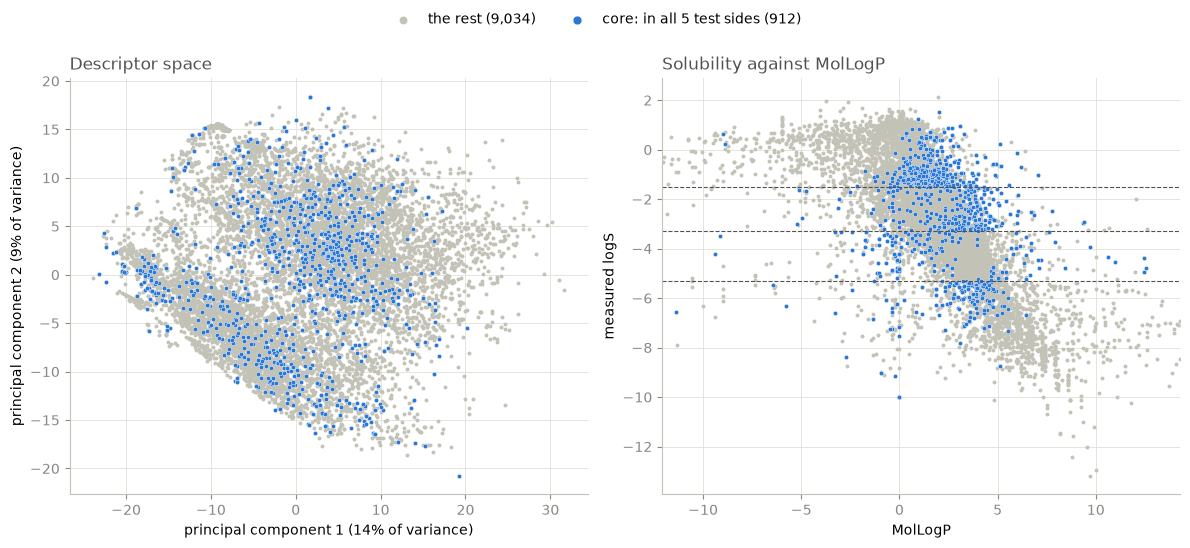

In [10]:
CORE, REST, INK, MUTED, GRID, AXIS = "#2a78d6", "#c3c2b7", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"  # as in 01_prep_and_analysis.ipynb
CORE_LABEL, REST_LABEL = f"core: in all {len(LS_SPLITS)} test sides ({core.sum():,})", f"the rest ({(~core).sum():,})"


def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(AXIS)
    ax.tick_params(colors=MUTED)
    ax.grid(color=GRID, lw=0.6)
    ax.set_axisbelow(True)


pca = PCA(n_components=2).fit(Z.numpy())
pcs = pca.transform(Z.numpy())

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (xs, ys) in zip(axes, [(pcs[:, 0], pcs[:, 1]), (features["MolLogP"].to_numpy(), logS["mean"].to_numpy())]):
    ax.scatter(xs[~core], ys[~core], s=8, color=REST, lw=0, label=REST_LABEL)
    ax.scatter(xs[core], ys[core], s=10, color=CORE, edgecolor="white", lw=0.3, label=CORE_LABEL)
    style(ax)
for b in boundaries:
    axes[1].axhline(b, color=INK, ls="--", lw=0.8)
var = 100 * pca.explained_variance_ratio_
axes[0].set(xlabel=f"principal component 1 ({var[0]:.0f}% of variance)", ylabel=f"principal component 2 ({var[1]:.0f}% of variance)")
axes[0].set_title("Descriptor space", loc="left", color=INK)
axes[1].set(xlabel="MolLogP", ylabel="measured logS", xlim=np.nanpercentile(features["MolLogP"], [0.5, 99.5]))
axes[1].set_title("Solubility against MolLogP", loc="left", color=INK)
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, loc="upper center", ncol=2, markerscale=2)
fig.tight_layout(rect=(0, 0, 1, 0.93))

### Descriptors that set the core apart

For each descriptor, the AUC of telling core compounds from the rest by that descriptor alone, as for the test sides above. The plots show the eight furthest from 0.5, as the share of each group per bin, over the range holding 98% of compounds (the 1st to 99th percentile), so a few extreme values don't squeeze the rest.

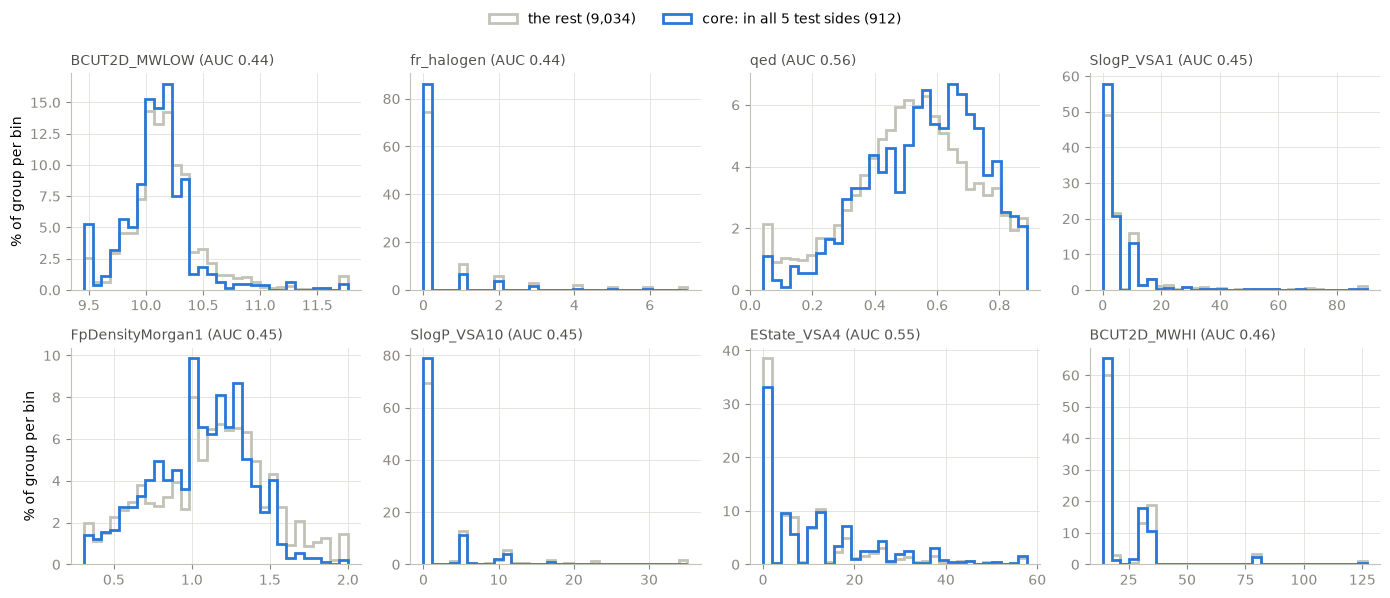

In [11]:
core_auc = pd.Series([roc_auc_score(core[ok], X[ok, j]) for j in range(X.shape[1]) for ok in [~np.isnan(X[:, j])]], index=features.columns)
apart_most = core_auc.sub(0.5).abs().nlargest(8).index

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, name in zip(axes.flat, apart_most):
    x = features[name].to_numpy()
    bins = np.linspace(*np.nanpercentile(x, [1, 99]), 31)
    for mask, color, label in [(~core, REST, REST_LABEL), (core, CORE, CORE_LABEL)]:
        shown = np.clip(x[mask & ~np.isnan(x)], bins[0], bins[-1])  # values outside the range pile into the end bins
        ax.hist(shown, bins=bins, weights=np.full(len(shown), 100 / len(shown)), histtype="step", lw=2, color=color, label=label)
    ax.set_title(f"{name} (AUC {core_auc[name]:.2f})", loc="left", color=INK, fontsize=10)
    style(ax)
for ax in axes[:, 0]:
    ax.set_ylabel("% of group per bin")
fig.legend(*axes[0, 0].get_legend_handles_labels(), frameon=False, loc="upper center", ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.94))

### Core structures

Twenty-four core compounds drawn at random, each labelled with its measured logS (the mean over its unflagged votes) and number of votes.

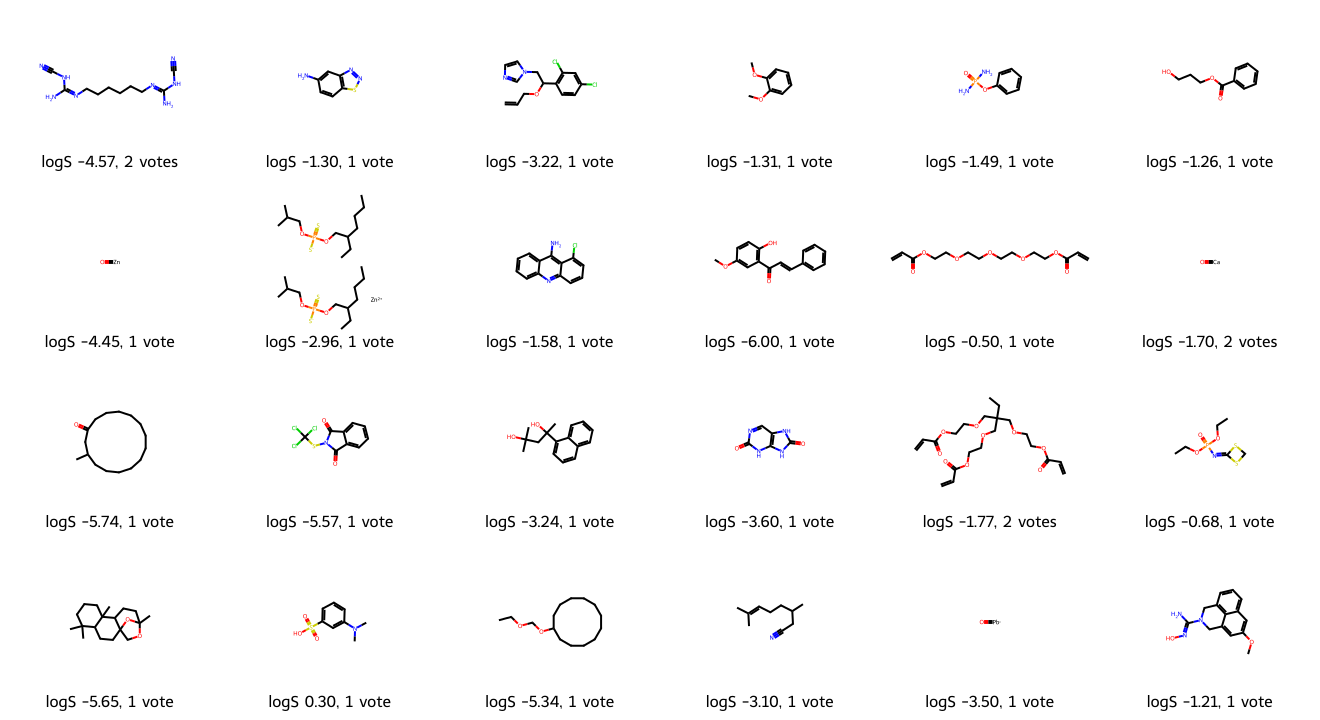

In [12]:
n_votes = np.bincount(compound, minlength=n_compounds)
shown = np.random.default_rng(0).choice(np.flatnonzero(core), size=24, replace=False)
Draw.MolsToGridImage(
    [Chem.MolFromSmiles(smiles.iloc[i]) for i in shown],
    legends=[f"logS {logS['mean'].iloc[i]:.2f}, {n_votes[i]} vote{'s' if n_votes[i] > 1 else ''}" for i in shown],
    molsPerRow=6,
    subImgSize=(220, 180),
)

### Reading the core

- **Hard on any split.** The forest gets core compounds right only 21% of the time even in random cross-validation, against 91% for the compounds no seed put in test. The learned splits gathered compounds that are hard anywhere; they didn't make them hard.
- **Near the boundaries.** The core sits closer to a tier boundary than the compounds no seed put in test (median 0.43 against 0.74 logS), so part of its difficulty is that a small error in logS crosses a boundary. That fits the hard-split errors being mostly one tier off.
- **The seeds agree.** Test sides overlap by 0.46–0.54 against the 0.13 expected of independent random sides of this size, and 912 compounds are in all five.
- **A multivariate signature exists where no univariate one does.** One descriptor at a time, the core is invisible (AUCs within 0.08 of 0.5). Together, the 152 descriptors let a forest find it with a held-out AUC of 0.77. So the core is partly a region of descriptor space after all — not a region the training data lacks (the test sides hold familiar chemistry), but a region where the solubility the descriptors imply and the solubility measured systematically part ways. The descriptor plots above show which features lean; each leans only moderately, so the signature is a combination, not one feature.
- **Mostly measured once.** Only 103 of the 912 core compounds (11%) have 2+ unflagged votes, fewer than among the compounds no seed put in test (14%). For most of the core the data cannot say whether the value or the descriptors are off. Of the 103, 24% have votes in two or more tiers, against 7% of repeats no seed put in test.
- **Flags do not explain it, and cannot.** Compounds with a flagged vote are rare everywhere (0.4–1.4%) and no more common in the core (1.0%) than in the groups around it. The prep notebook's flags catch gross errors among compounds with 3+ votes; the core is 89% single-vote compounds, exactly the population a flag can never reach, which carries the prep notebook's ~6% error rate as a prior instead. On that prior, roughly 400–700 single-vote compounds in the data hold a wrong label — the same order as the core's 809 single-vote members. The core is where such compounds would surface; whether most of it *is* wrong labels or a representation gap is what the values alone cannot settle.
- **Discordant repeats sit just outside the core.** Compounds in two to four test sides are the most often repeated (19–26%) and the most discordant (48–57% with votes in two or more tiers). Part of that is built in: a compound whose votes fall in two tiers can be at most partly right, so the gap loss pushes it toward test, and which seeds take it varies.

That leaves two explanations for a core compound, now sharpened: the descriptors carry a signature of these compounds but place them in the wrong tier — a representation that sees *that* they differ without seeing *how*, as with a condition such as ionization state or crystal form — or the models fail to use what the descriptors hold. Next, [06_knn.ipynb](06_knn.ipynb) separates the two with nearest neighbours, which fit no function, under the descriptors and structural fingerprints. The learned splits and the core are in `data/aqsoldb_splits_ls.csv`.